# Visualisations simples des tirs de la LNH

Ce notebook présente des visualisations agrégées à partir des données ordonnées des tirs et des buts de la LNH.

In [1]:
%matplotlib inline

import pandas as pd
import matplotlib.pyplot as plt

# Charger le jeu de données ordonné produit à la tâche 3
shots = pd.read_csv("../data/processed/shots.csv")


## 1. Comparaison des types de tirs

Pour cette analyse, nous utilisons la saison régulière 2023-2024. Les tirs de toutes les équipes sont regroupés par type de tir afin de comparer leur fréquence, le nombre de buts marqués et leur pourcentage de buts.

In [2]:
# Sélectionner uniquement la saison régulière 2023-2024
season_2023 = shots[
    (shots["season"] == 20232024) &
    (shots["game_type"] == 2)
].copy()

# Agréger les événements par type de tir
shot_type_stats = (
    season_2023
    .dropna(subset=["shot_type"])
    .groupby("shot_type")
    .agg(
        tirs=("shot_type", "size"),
        buts=("is_goal", "sum")
    )
)

# Calculer le pourcentage de buts pour chaque type de tir
shot_type_stats["pourcentage_buts"] = (
    100 * shot_type_stats["buts"] / shot_type_stats["tirs"]
)

# Trier les types de tirs du plus fréquent au moins fréquent
shot_type_stats = shot_type_stats.sort_values("tirs", ascending=False)


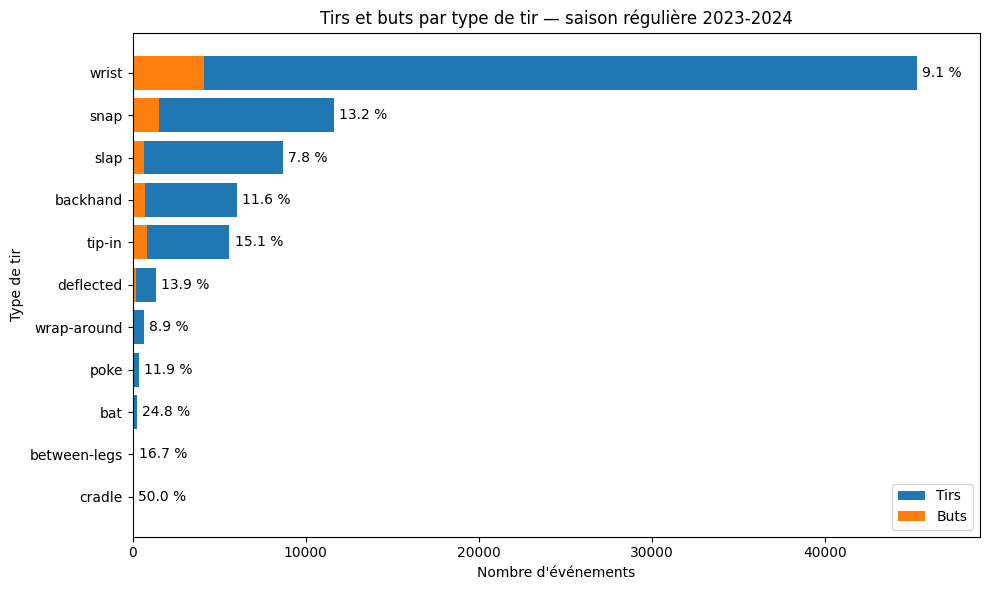

In [3]:
# Préparer les données dans l'ordre utilisé pour le graphique
fig, ax = plt.subplots(figsize=(10, 6))
stats_plot = shot_type_stats.sort_values("tirs")

# Superposer le nombre total de tirs et le nombre de buts
ax.barh(stats_plot.index, stats_plot["tirs"], label="Tirs")
ax.barh(stats_plot.index, stats_plot["buts"], label="Buts")

# Ajouter le pourcentage de buts à droite de chaque barre
for i, (tirs, pct) in enumerate(
    zip(stats_plot["tirs"], stats_plot["pourcentage_buts"])
):
    ax.text(
        tirs + 300,
        i,
        f"{pct:.1f} %",
        va="center"
    )

# Mise en forme du graphique
ax.set_xlabel("Nombre d'événements")
ax.set_ylabel("Type de tir")
ax.set_title("Tirs et buts par type de tir — saison régulière 2023-2024")
ax.legend(loc="lower right")
ax.set_xlim(0, stats_plot["tirs"].max() * 1.08)

plt.tight_layout()
plt.show()


### Discussion

Pour la saison régulière 2023-2024, le tir du poignet (*wrist shot*) est de loin le type de tir le plus fréquent, avec 45 321 événements. Il produit également le plus grand nombre total de buts, mais son pourcentage de buts est d'environ 9,1 %.

Le type *cradle* possède le pourcentage de buts observé le plus élevé (50 %), mais ce résultat repose sur seulement 6 tirs et n'est donc pas très représentatif. Parmi les types de tirs ayant un nombre d'observations beaucoup plus important, les *tip-ins* semblent particulièrement dangereux, avec un pourcentage de buts d'environ 15,1 %, suivis des *snap shots* avec environ 13,2 %.

On a choisi un diagramme à barres horizontales superposées, car il permet de comparer directement le nombre total de tirs et le nombre de buts pour chaque type de tir. L'ajout du pourcentage de buts à côté de chaque barre permet également de distinguer la fréquence d'un type de tir de son efficacité.

## 2. Relation entre la distance du tir et la probabilité de but

On analyse les saisons régulières 2018-2019, 2019-2020 et 2020-2021. Les tirs sont regroupés par intervalles de distance de 5 pieds afin d'estimer le pourcentage de buts en fonction de la distance au filet.

Nous avons remarqué qu'avant la saison 2019-2020 il n'avait pas le caractéristique que nous avions besoin pour calculer la distance de tir, dans ce cas, la façon la plus simple et logique pour nous était de calculer la shot_distance avec les données normalisées (demandé à la question 5) qui ne prenait pas en compte le coté de l'équipe. Ce qui fait en sorte que nous devons appeler normalize_shots et reconstruire le dataset ensuite. C'est un peu bizarre, mais c'était le plus simple que nous avons trouvé, à long terme probablement que nous allons devoir changer cette méthode qui n'est pas du tout intuitive.

In [4]:
from ift6758.features.shot_features import (
    normalize_shots,
)
from ift6758.features.build_dataset import build_dataset

normalize_shots()
build_dataset()
shots = pd.read_csv("../data/processed/shots.csv")

CSV : /home/hugo/Master/M1 UdeM/Automne/ISD/IFT3700_Projet1/data/processed/shots.csv
Matchs : 10395
Événements : 650432 | Buts : 63546
Colonnes : 26 | Doublons : 0

Valeurs manquantes :
 game_id                  0
event_id                 0
season                   0
game_type                0
game_date                0
period                   0
period_type              0
time_in_period           0
event_type               0
is_goal                  0
team_id                  0
team_name                0
x_coord                 16
y_coord                 15
zone_code               14
shooter_id               0
shooter_name             0
goalie_id             3268
goalie_name           3268
shot_type               80
empty_net             4597
strength              4597
strength_category    20731
situation_code           0
shot_distance           17
shot_angle            4233

Exclusions pour une analyse nécessitant :
  x_coord, y_coord : 17 événement(s) exclu(s)
  shot_distance : 17 é

In [5]:
# Saisons demandées pour l'analyse de la distance
seasons_q2 = [20182019, 20192020, 20202021]

# Conserver les matchs de saison régulière avec une distance connue
# et exclure les tirs dans un filet désert ou dont l'état du filet est inconnu
distance_data = shots[
    (shots["season"].isin(seasons_q2)) &
    (shots["game_type"] == 2) &
    (shots["shot_distance"].notna()) &
    (shots["empty_net"] == False)
].copy()

# Regrouper les distances par intervalles de 5 pieds
distance_data["distance_bin"] = (
    distance_data["shot_distance"] // 5 * 5
)

# Calculer le nombre de tirs et de buts pour chaque saison et intervalle
distance_stats = (
    distance_data
    .groupby(["season", "distance_bin"])
    .agg(
        tirs=("is_goal", "size"),
        buts=("is_goal", "sum")
    )
    .reset_index()
)

# Calculer le pourcentage de buts dans chaque intervalle de distance
distance_stats["pourcentage_buts"] = (
    100 * distance_stats["buts"] / distance_stats["tirs"]
)

# Exclure les intervalles avec trop peu d'observations
plot_stats = distance_stats[distance_stats["tirs"] >= 100].copy()


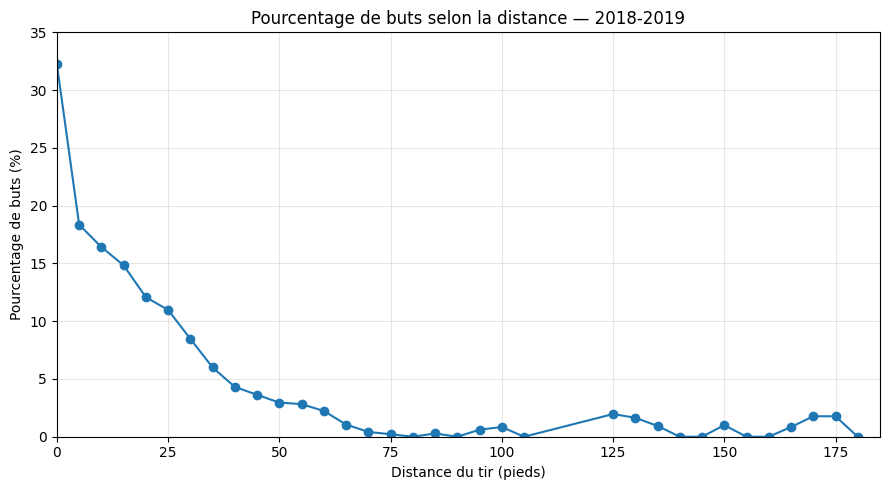

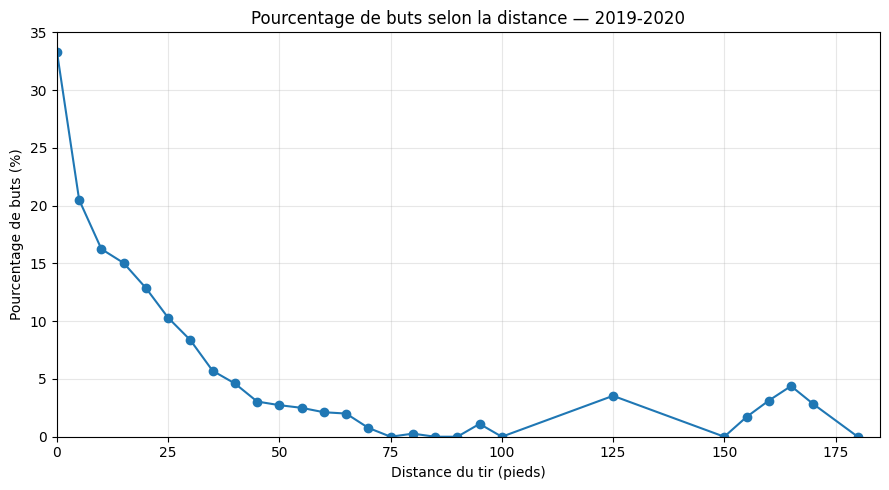

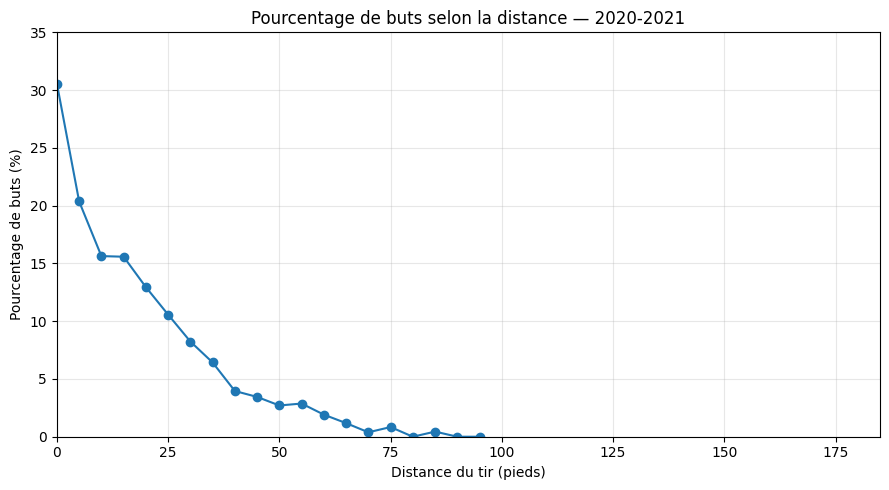

In [6]:
# Libellés lisibles pour les titres des graphiques
season_labels = {
    20182019: "2018-2019",
    20192020: "2019-2020",
    20202021: "2020-2021"
}

# Utiliser la même échelle horizontale pour faciliter la comparaison
max_distance = plot_stats["distance_bin"].max()

# Produire une figure distincte pour chaque saison
for season in seasons_q2:
    season_stats = plot_stats[
        plot_stats["season"] == season
    ].copy()

    fig, ax = plt.subplots(figsize=(9, 5))

    ax.plot(
        season_stats["distance_bin"],
        season_stats["pourcentage_buts"],
        marker="o"
    )

    # Mise en forme commune aux trois saisons
    ax.set_xlabel("Distance du tir (pieds)")
    ax.set_ylabel("Pourcentage de buts (%)")
    ax.set_title(
        f"Pourcentage de buts selon la distance — {season_labels[season]}"
    )

    ax.set_xlim(0, max_distance + 5)
    ax.set_ylim(0, 35)
    ax.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()


### Discussion

Dans les trois saisons étudiées, on observe une relation claire entre la distance du tir et la probabilité de marquer : plus un tir est effectué près du filet, plus son pourcentage de buts est élevé. Le pourcentage diminue rapidement lorsque la distance augmente, et devient généralement très faible pour les tirs plus éloignés.

Les tendances observées en 2018-2019, 2019-2020 et 2020-2021 sont assez similaires. Il n'y a donc pas de changement majeur dans la relation générale entre la distance et la probabilité de marquer au cours de ces trois saisons.

Les tirs dans un filet désert ainsi que les événements pour lesquels l'état du filet est inconnu ont été exclus afin d'éviter qu'ils influencent artificiellement la relation entre la distance et le pourcentage de buts. De plus, les intervalles contenant moins de 100 tirs ont été exclus afin de limiter les estimations instables dues à de petits échantillons.

On a choisi une courbe avec des points pour représenter cette relation, car la distance est une variable ordonnée et cette représentation permet de visualiser facilement l'évolution du pourcentage de buts lorsque la distance au filet augmente.

## 3. Pourcentage de buts selon la distance et le type de tir

Pour cette analyse, nous utilisons la saison régulière 2023-2024. Les tirs sont regroupés par type et par intervalles de distance de 5 pieds afin de comparer leur pourcentage de buts.

In [7]:
# Sélectionner la saison régulière 2023-2024 avec les informations nécessaires
q3_data = shots[
    (shots["season"] == 20232024) &
    (shots["game_type"] == 2) &
    (shots["shot_distance"].notna()) &
    (shots["shot_type"].notna()) &
    (shots["empty_net"] == False)
].copy()

# Regrouper les distances par intervalles de 5 pieds
q3_data["distance_bin"] = q3_data["shot_distance"] // 5 * 5

# Agréger par type de tir et par intervalle de distance
q3_stats = (
    q3_data
    .groupby(["shot_type", "distance_bin"])
    .agg(
        tirs=("is_goal", "size"),
        buts=("is_goal", "sum")
    )
    .reset_index()
)

# Calculer le pourcentage de buts pour chaque combinaison
q3_stats["pourcentage_buts"] = (
    100 * q3_stats["buts"] / q3_stats["tirs"]
)

# Limiter les fluctuations dues aux très petits échantillons
q3_plot = q3_stats[q3_stats["tirs"] >= 50].copy()

# Conserver les types de tirs principaux avec suffisamment de données
main_shot_types = ["wrist", "snap", "slap", "backhand", "tip-in"]

q3_final = q3_plot[
    q3_plot["shot_type"].isin(main_shot_types)
].copy()


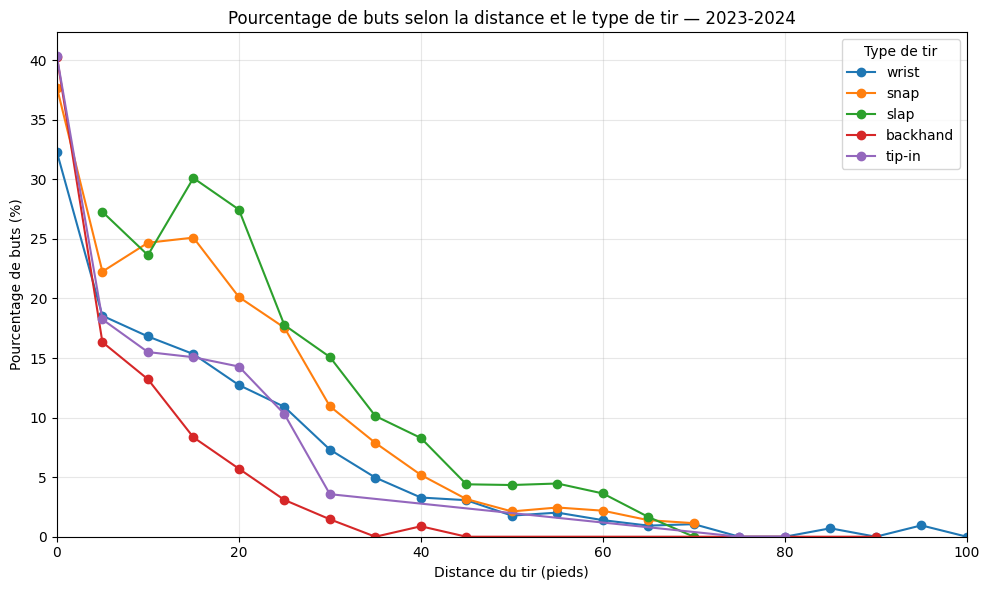

In [8]:
fig, ax = plt.subplots(figsize=(10, 6))

# Tracer une courbe par type de tir
for shot_type in main_shot_types:
    type_data = q3_final[
        q3_final["shot_type"] == shot_type
    ].sort_values("distance_bin")

    ax.plot(
        type_data["distance_bin"],
        type_data["pourcentage_buts"],
        marker="o",
        label=shot_type
    )

# Mise en forme du graphique comparatif
ax.set_xlabel("Distance du tir (pieds)")
ax.set_ylabel("Pourcentage de buts (%)")
ax.set_title(
    "Pourcentage de buts selon la distance et le type de tir — 2023-2024"
)

ax.set_xlim(left=0, right=100)
ax.set_ylim(bottom=0)

ax.grid(alpha=0.3)
ax.legend(title="Type de tir")

plt.tight_layout()
plt.show()


### Discussion

La probabilité de marquer diminue globalement avec la distance pour tous les types de tirs. Cette tendance confirme que la distance au filet reste un facteur important, peu importe le type de tir.

Cependant, certains types de tirs semblent plus dangereux à courte distance. Les *slap shots* et les *snap shots* présentent des pourcentages de buts relativement élevés dans plusieurs intervalles proches du filet. Les *wrist shots* sont observés sur une plage de distances beaucoup plus large et montrent une diminution plus régulière du pourcentage de buts lorsque la distance augmente.

Les *backhands* deviennent rapidement moins efficaces lorsque la distance augmente. Les *tip-ins* sont surtout observés très près du filet, ce qui est cohérent avec la nature de ce type de tir.

On a retenu uniquement les intervalles contenant au moins 50 tirs afin de limiter les fluctuations dues à de petits échantillons. Les tirs dans un filet désert ont également été exclus pour éviter de fausser la relation entre la distance, le type de tir et la probabilité de marquer.